# Lab 2: Word Embeddings

In this lab, you will:
- Get familiar with the `gensim` library and word with pre-trained word embeddings
- Train your own embeddings from scratch using Word2Vec

In the first part of the lab, you will work with GloVe pre-trained embeddings. In the second part, you will train your own Word2Vec model. There is also an additional exercise about improving embedding quality through semantic similarity.

## Exercises

### Part 1: Working with pre-trained embeddings

Let's prepare the environment by installing the gemsin package and importing the datasets.

In [ ]:
# to begin with we have to first install the library
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 34.7 MB/s eta 0:00:00


In [ ]:
!git clone https://github.com/elsartori/Lab_2_datasets.git

Cloning into 'Lab_2_datasets'...
remote: Enumerating objects: 28, done.
remote: Counting objects: 100% (28/28), done.
remote: Compressing objects: 100% (26/26), done.
remote: Total 28 (delta 7), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (28/28), 27.52 MiB | 20.86 MiB/s, done.
Resolving deltas: 100% (7/7), done.


In [ ]:
import gensim
# gensim.downloader is an API for downloading, getting information and loading datasets and models
import gensim.downloader as api

We load the pre-trained GloVe embeddings.

In [ ]:
# we load the embeddings
embeddings = api.load('glove-wiki-gigaword-300')

[==================================================] 100.0% 376.1/376.1MB downloaded


#### **Ex.1**

Find the 10 most similar words (with the highest cosine similarity) to "people", "men", "women" and "children", without using Gensim `most_similar` function. Use the GloVe embeddings saved in `embeddings`.

You might find the function [```numpy.argsort```](https://numpy.org/doc/2.1/reference/generated/numpy.argsort.html) useful.

Previously we obtained the following results:

* Most similar words to `people`: 'others','those','least','many','some','all','them','thousands','hundreds','there'
* Most similar words to `men`: 'women','man','soldiers','who','boys','young','male','they','girls','four'
* Most similar words to `women`: 'men','girls','female','woman','male', 'mothers','athletes','she','young','children'
* Most similar words to `children`: 'parents','child','kids','daughters', 'girls', 'youngsters','mothers','adults','teenagers','babies'

In [ ]:
import numpy as np

In [ ]:
#Ex 1
words_of_interest = ["people", "men", "women", "children"]

# find the 10 most similar words to words_of_interest
for word in words_of_interest:
  similarities = [embeddings.similarity(word, x) for x in embeddings.key_to_index]
  top_10_indices = np.argsort(similarities)[::-1][1:11]
  most_similar_words = [embeddings.index_to_key[i] for i in top_10_indices]
  print("Most similar words to", word, ":", most_similar_words)

Most similar words to people : ['others', 'those', 'least', 'many', 'some', 'all', 'them', 'thousands', 'hundreds', 'there']
Most similar words to men : ['women', 'man', 'soldiers', 'who', 'boys', 'young', 'male', 'they', 'girls', 'four']
Most similar words to women : ['men', 'girls', 'female', 'woman', 'male', 'mothers', 'athletes', 'she', 'young', 'children']
Most similar words to children : ['parents', 'child', 'kids', 'daughters', 'girls', 'youngsters', 'mothers', 'adults', 'teenagers', 'babies']


### Part 2 : Training your own embeddings

We will now see how to train your own embeddings. We will use a dataset containing posts during the first year of the pandemic (january-december 2020). In total it contains 63806 entries.

In [ ]:
# let's visualize the dataset
import pandas as pd
# we read the excel into a dataframe and visualize the first rows
covid_df = pd.read_excel('/content/Lab_2_datasets/Covid_dataset_en.xlsx')
covid_df.head()

,PostID,Post Description,Date,Language Code,Full Language,Sentiment
0,B7mbLCVhYIf,QUESTIONS AND ANSWERS ON CORONAVIRUS PT. 2\n\n...,2020-01-21,en,English,positive
1,B7m7M3SgvI1,Using humor to bring attention to a serious ma...,2020-01-22,en,English,negative
2,B7oK_DMhtxr,Stay safe\nCover your face\n#typ262 #40mm #40m...,2020-01-22,en,English,positive
3,B7njeFbBX5y,Did you know an outbreak of a new coronavirus ...,2020-01-22,en,English,negative
4,B7nV26QgOLP,It’s so sad and scary that the coronavirus has...,2020-01-22,en,English,negative


To start we need to 1) lowercase the text and 2) clean the dataset from common characters that might be present. If we don't do this, we risk getting multiple vectors for the same word like: `CORONAVIRUS`, `coronavirus`, `coronavirus.` or `#coronavirus`.

In [ ]:
import re
# we lowercase all entries in the column
covid_df['Post Description'] = covid_df['Post Description'].str.lower()
# we remove common punctuation marks
covid_df['Post Description'] = covid_df['Post Description'].map(lambda x: re.sub(r'[\[\]()/\-\_#@.!?,;.:]', '', str(x)))
# we remove newline characters
covid_df['Post Description'] = covid_df['Post Description'].map(lambda x: re.sub('\n', ' ', str(x)))
covid_df.head()

,PostID,Post Description,Date,Language Code,Full Language,Sentiment
0,B7mbLCVhYIf,questions and answers on coronavirus pt 2 is ...,2020-01-21,en,English,positive
1,B7m7M3SgvI1,using humor to bring attention to a serious ma...,2020-01-22,en,English,negative
2,B7oK_DMhtxr,stay safe cover your face typ262 40mm 40mmpers...,2020-01-22,en,English,positive
3,B7njeFbBX5y,did you know an outbreak of a new coronavirus ...,2020-01-22,en,English,negative
4,B7nV26QgOLP,it’s so sad and scary that the coronavirus has...,2020-01-22,en,English,negative


Different tasks require different preprocessing techniques. For example, if we were working on sentiment classification we could want to keep punctuation marks that express some degree of emphasis, like `!` or `?`.

Other common preprocessing steps are **stopwords removal** and **stemming** or **lemmatization**.

**Stopwords** are frequently used words that do not have any specific meaning, like `the`, `a`, `an`. As they do not add information, they are generally removed to make processing a text faster and to avoid wasting memory on embeddings that are not important.

**Stemming** and **lemmatization** are two NLP techniques with the goal of reducing the vocabulary size. The goal of these techniques is to reduce multiple forms of a same word to a single one (e.g., `run`, `running`, `runs` -> `run`).

**Stemming** removes all common suffixes from words to obtain the root, however the result can sometimes be a little malformed or straight up incorrect (e.g., `vaccination` -> `vaccin` or `caring` -> `car`)

**Lemmatization**, instead, assigns each word to its base form to a lemma, a regular word that could be found in a dictionary (e.g., `vaccination` -> `vaccine` or `caring` -> `care`). To assign the correct lemma to each word, lemmatizers are usually employed along with POS taggers, as words might assume different lemmas depending on their Part-Of-Speech tag:
* He is **running** away -> running is verb -> lemma=`run`
* **Running** is healthy for you -> running is a noun -> lemma=`running`


In [ ]:
import nltk

# we use nltk list of stopwords
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words = stopwords.words('english')
print(stop_words)

# sometimes we may want to add additional words to the list, this can be done using the following line of code:
# stop_words.extend(["example"])

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", 'her', 'here', 'hers', 'herself', "he's", 'him', 'himself', 'his', 'how', 'i', "i'd", 'if', "i'll", "i'm", 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', "i've", 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own', 're', 's', 'same', 'shan', "shan't", 'she

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
from gensim.test.utils import common_texts
import spacy

# we use spacy lemmatizer
# in addition to a pos tagger, spacy pipeline also includes a parser and named entity recognition
# we won't be using them, so we disable those options
lemma = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

# we create a list with all the posts
posts = covid_df['Post Description'].values.tolist()

# we run the lemmatizer and remove words that are stopwords
preprocessed_posts = []
for lemmatized_post in lemma.pipe(covid_df['Post Description']):
    preprocessed_posts.append(" ".join(word.lemma_ for word in lemmatized_post if word.lemma_ not in stop_words))

Let's see what the final result is!

In [ ]:
print("ORIGINAL: ", posts[0])
print("PROCESSED: ", preprocessed_posts[0])

ORIGINAL:  questions and answers on coronavirus pt 2  is there a vaccine for coronavirus  when a disease is new there is no vaccine until one is developed it can take a number of years for a new vaccine to be developed  is there a treatment for a novel coronavirus  there is no specific treatment for disease caused by a novel coronavirus however many of the symptoms can be treated and therefore treatment based on the patient’s clinical condition moreover supportive care for infected persons can be highly effective  what can i do to protect myself  standard recommendations to reduce exposure to and transmission of a range of illnesses include maintaining basic hand and respiratory hygiene and safe food practices  and avoiding close contact when possible with anyone showing symptoms of respiratory illness such as coughing and sneezing  coronavirus coronavirusawareness coronavirusoutbreak
PROCESSED:  question answer coronavirus pt 2   vaccine coronavirus   disease new vaccine one develop t

We can save the preprocessed posts in a new column of the dataframe, for easy access.

In [ ]:
covid_df["preprocessed_posts"] = preprocessed_posts

We can now train our [Word2Vec](https://radimrehurek.com/gensim/models/word2vec.html) Gensim model!
The main arguments are:
* ```sentences [iterable of iterables] ``` : list of lists of tokens (words) from the corpora.
* ```vector_size  [int] ``` : optional, dimension of the word vectors.
* ```window  [int] ```: optional, size of the window.
* ```min_count  [int] ```: optional, ignore words with a total frequency lower than the given value.
* ```seed  [int] ```: optional, set seed for random generator, useful for reproducibility results.
* ```max_vocab_size  [int] ```: optional, limit the maximum size of the learned vocabulary.
* ```workers  [int] ```: optional, number of threads to be used during training. To ensure reproducible results it should be set to 1.
* ```sg  [int] ```: optional 0/1, if 1 skip-gram will be used, otherwise CBOW is used.

**See the documentation for the full list!**

`preprocessed_posts` is a list of strings, but the model takes a list of lists of tokens as input, we have to tranform it.

In [ ]:
# we split each string into a list of words
preprocessed_posts = [post.split(" ") for post in preprocessed_posts]

In [ ]:
# we import the model
from gensim.models import Word2Vec

# we set the seeds needed to ensure reproducibility of results
import os
import random
os.environ['PYTHONHASHSEED']=str(123)
np.random.seed(0)
random.seed(0)

# we instantiate the model and training starts automatically
model = Word2Vec(preprocessed_posts, seed=0, window=7, min_count=5, max_final_vocab=50000, vector_size=300, workers=1)
# we can get the trained vectors as KeyedVectors
word_vectors = model.wv

If we are done training and no longer need the full state of the model, we can extract the learned vectors as KeyedVectors and use those directly for faster loading and computation.

In [ ]:
# we can save the model in case we may need it
model.save("word2vec_covid_trained.model")

# to load it back we just use the following instruction
# model = Word2Vec.load("word2vec_covid_trained.model")

# we can also save and load the trained word vectors
word_vectors.save("word2vec_covid_trained.wordvectors")

#from gensim.models import KeyedVectors
#reloaded_word_vectors = KeyedVectors.load('word2vec_covid_trained.wordvectors')

# we delete the model as we don't need to train it further
del model

Let's look at the words most similar to those commonly associated with the coronavirus epidemic.

In [ ]:
print(word_vectors.most_similar('covid', topn=5))
print(word_vectors.most_similar('coronavirus', topn=5))
print(word_vectors.most_similar('pandemic', topn=5))
print(word_vectors.most_similar('epidemic', topn=5))

[('infora', 0.44129911065101624), ('doctor', 0.41796180605888367), ('covid19', 0.4148882329463959), ('pandemic2020', 0.3707214593887329), ('helpfightcorona', 0.35946083068847656)]
[('virus', 0.5774295926094055), ('covidー19', 0.508964478969574), ('covid19', 0.5015876293182373), ('coronaviruspandemic', 0.46379977464675903), ('vaccination', 0.4353228509426117)]
[('crisis', 0.7150174975395203), ('outbreak', 0.6074318289756775), ('situation', 0.5117709040641785), ('challenge', 0.48794999718666077), ('consequence', 0.4859544038772583)]
[('contagious', 0.734600841999054), ('sar', 0.7270676493644714), ('ebola', 0.6919759511947632), ('cholera', 0.69072425365448), ('worsen', 0.6636701226234436)]


#### **Ex.2**

We will now split the dataset of covid posts and train two Word2Vec models:
*   `model_first_months` on posts from the start of January to the end of June;
*   `model_last_months` on posts from the start of July up until the end of December.

You are also given a list of terms named `vocabs` = ['covid', 'coronavirus', 'covid19', 'corona', 'pandemic', 'epidemic', 'outbreak', 'lockdown', 'quarantine', 'mental', 'vaccine', 'vaccination', 'virus', 'sick',
 'ill', 'illness' ,'testing', 'hospital', 'doctor', 'doctors', 'nurse', 'nurses', 'medic', 'medical', 'medicine', 'prevention', 'health', 'safe',
 'care', 'worry', 'recession', 'job', 'life', 'live', 'school']


The exercise consists in:
1.   Instantiate and train the Word2Vec models
2.   Take each term in vocabs and compare it in the following way:
      * get the list of **50** most similar words from `model_first_months`
      * get the list of **50** most similar words from `model_last_months`
      * count the words in common between the two
3.   Extract the 10 words (among `vocabs`) that changed the most, the ones that have the lowest number of common words between the models
4.   Save the 10 words as a list in a variable called `ten_most_changed`

Remember that we previously saved the preprocessed posts in the column 'preprocessed_posts'.


Both Word2Vec models must have the following paramenters:
* seed=0
* window=5
* min_count=5
* max_final_vocab=50000
* vector_size=300
* workers=1

**Before training the models, remember to set all seeds and `workers`=1 or you are going to obtain different results!!**

In [ ]:
# we convert the Date column to type datetime. This allows us to use logical operators (<,>, ==,...) on dates correctly, otherwise they'll be interpreted as strings
covid_df['Date'] = pd.to_datetime(covid_df['Date'], format='%m/%d/%Y')
# cutoff for the two datasets
middle = '2020-06-30'
# extract first 6 months
mask = (covid_df["Date"] <= middle)
covid_first_months = covid_df[mask]
# extract last 6 months
mask = (covid_df["Date"] > middle)
covid_last_months = covid_df[mask]

In [ ]:
# list of terms that we are interested in
vocabs = ['covid', 'coronavirus', 'covid19', 'corona', 'pandemic', 'epidemic', 'outbreak', 'lockdown', 'quarantine', 'mental', 'vaccine', 'vaccination', 'virus', 'sick',
 'ill', 'illness' ,'testing', 'hospital', 'doctor', 'doctors', 'nurse', 'nurses', 'medic', 'medical', 'medicine', 'prevention', 'health', 'safe',
 'care', 'worry', 'recession', 'job', 'life', 'live', 'school']

In [ ]:
#Ex.2
# train model on first months
posts_first_months = [post.split(" ") for post in covid_first_months["preprocessed_posts"].values.tolist()]
model_first_months = Word2Vec(posts_first_months, seed=0, window=5, min_count=5, max_final_vocab=50000, vector_size=300, workers=1)
wv_first_months = model_first_months.wv
# train model on last months
posts_last_months = [post.split(" ") for post in covid_last_months["preprocessed_posts"].values.tolist()]
model_last_months = Word2Vec(posts_last_months, seed=0, window=5, min_count=5, max_final_vocab=50000, vector_size=300, workers=1)
wv_last_months = model_last_months.wv
# compare terms and get the 10 most changed words
vocabs_changed = {}
for vocab in vocabs:
  similar_words_first_months = list(map(lambda x: x[0], wv_first_months.most_similar(vocab, topn=50)))
  similar_words_last_months = list(map(lambda x: x[0], wv_last_months.most_similar(vocab, topn=50)))
  # check the length of the intersection to count how many common words
  vocabs_changed[vocab] = len(set(similar_words_first_months) & set(similar_words_last_months))

# sort the dictionary
sorted_vocabs_changed = dict(sorted(vocabs_changed.items(), key=lambda x: x[1]))
# get the first 10 keys of the dictionary
ten_most_changed = list(sorted_vocabs_changed.keys())[:10]

print("----Exercise 2----")
print(ten_most_changed)

----Exercise 2----
['vaccination', 'recession', 'nurses', 'medic', 'doctors', 'prevention', 'corona', 'live', 'vaccine', 'epidemic']


#### **Ex.3**

We can use semantic lexicons such as WordNet to refine word embeddings in a post-processing step called **[retrofitting](https://aclanthology.org/N15-1184.pdf)**.

Idea: two words that are synoynms (or semantically related) in WordNet should have similar vector representation.

The lexicon (WordNet in our case) is represented as an undirected graph $(V, E)$, where each node is a word and each edge $(w_i, w_j) \in E$ indicates a semantic relation (e.g. synonymy, hypernymy).

Let's take *plant* as example:
- *plant.n.01* has as neighbors its synonyms *works*, *industrial plant* and its hypernym *facility*

- *plant.n.02* has as neighbors its synonyms *flora*, *plant life* and  its hypernym *organism*

So for example $(plant, works) \in E$ and $(plant, organism) \in E$
are both edges in the graph, representing different types of semantic relations.

Let's create our own semantic lexicon from Wordnet.
We should obtain a dictionary whose keys are the words in our vocabulary and the value is a list of neighbors (synoynms, hypernyms and hyponyms).

For computational reasons, we are going to build our lexicon for a selection of words (whose embeddings will be retrofitted).

In [ ]:
# list of words for which we have embeddings
full_vocab = list(word_vectors.key_to_index)
# we need a lexicon for the words we want to retrofit (only a subset)
vocabs_to_retrofit = full_vocab[:1500]

To build the lexicon, iterate over the words in `vocabs_to_retrofit` and collect
their neighbors in WordNet (synonyms, hypernyms and hyponyms) across all
synsets.

In [ ]:
import nltk
nltk.download('wordnet')

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
# Ex 3.1
from nltk.corpus import wordnet as wn

# maps each word to its list of neighbors in the lexicon
lexicon = {} # must have this structure: lexicon[word] = [neighbors]

# iterate over all words in the subset of words to retrofit and find its neighbors (synonyms, hypernyms and hyponyms) in WordNet by iterating over all its synsets
for word in vocabs_to_retrofit:
    neighbors = set()
    # iterate over all synsets (meanings) for the current word
    for synset in wn.synsets(word):
        # synonyms
        for lemma in synset.lemmas():
            neighbors.add(lemma.name().lower())
        # hypernyms
        for hypernym in synset.hypernyms():
            for lemma in hypernym.lemmas():
                neighbors.add(lemma.name().lower())
        # hyponyms
        for hyponym in synset.hyponyms():
            for lemma in hyponym.lemmas():
                neighbors.add(lemma.name().lower())
    if len(neighbors) > 0:
        lexicon[word] = list(neighbors)

# make sure the word itself is not included among its neighbors
# only add the word to the lexicon if it has at least one neighbor

The goal is to learn new vectors $Q$ that are simultaneously:

- **close to the original vectors** $\hat{Q}$ (preserve the distributional
  information learned)
- **close to lexicon neighbors** (incorporate semantic knowledge)

This is captured by the objective function:

$$L(Q) = \sum_{i=1}^n \left[ \alpha_i \| q_i - \hat{q}_i \|^2 + \sum_{j:(i,j) \in E} \beta_{ij} \| q_i - q_j \|^2 \right]$$

where $\hat{Q} = [\hat{q}_1, ..., \hat{q}_n]$ is the original embedding matrix (could be any pre-trained model) and $Q = [q_1, ..., q_n]$ is the learned embedding matrix.

The first term penalizes deviation from the original vector; the second penalizes
distance between neighboring words in the lexicon ($q_j, j:(i,j)\in E$). The parameters $\alpha_i$ control how strongly $q_i$ is pulled toward the original vector $\hat{q_i}$ and
$\beta_{ij}$ control how strongly $q_i$ is pulled toward its lexicon neighbors $q_j$.

The algorithm to find $Q$ is the following:
- **Initialize** $Q$ = $\hat{Q}$: start from the original vectors (the previously trained Word2Vec vectors)
- **Iterate** $T$ times:
  - For each word in the vocabulary, update $q_i$ by taking the derivative of $L(Q)$ with respect to $q_i$ and setting it to zero. This gives the closed-form update:

$$q_i = \frac{\sum_{j:(i,j) \in E} \beta_{ij} q_j + \alpha_i \hat{q}_i}{\sum_{j:(i,j) \in E} \beta_{ij} + \alpha_i}$$.

In practice, $T = 10$ iterations are sufficient for convergence.

You can use `deepcopy` to copy the original pre-trained vectors (the previously trained Word2Vec vectors).

Initially set $\alpha_i = 1$ and $\beta_{ij} = |degree(i)|^{-1}$, where $degree(i)$ denotes the set of neighbors of word $w_i$ in the lexicon graph.

Use different values of $\alpha$ and $\beta$ to observe how the balance between the original vectors and the lexicon neighbors affects the retrofitted vectors.


In [ ]:
#Ex 3.2
from copy import deepcopy

# initialize Q = Q_hat (word_vectors trained before)
retrofit_vectors = deepcopy(word_vectors)


# set parameters
## CODE HERE
T = 10
alpha = 1

# iterate T times
for it in range(T):

  # loop through every node in our lexicon
  for word, neighbors in lexicon.items():

    # count number of neighbors
    ## CODE HERE
    valid_neighbors = [n for n in neighbors if n in retrofit_vectors]
    num_neighbors = len(valid_neighbors)
    if num_neighbors == 0:
        continue
    # assign beta = 1/|deg(i)| = 1/(num_neighbors)a
    ## CODE HERE
    beta = 1.0 / num_neighbors
    # the numerator consists of two sums
    # numerator: alpha_i * q_hat_i, with alpha_i = 1
    ## CODE HERE
    num_part1 = alpha * word_vectors[word]
    # numerator: sum_beta_ij * q_j, with beta_ij = 1/|deg(i)|
    # iterate over neighbours (q_j) and compute the sum
    ## CODE HERE
    num_part2 = np.zeros(word_vectors.vector_size)
    for n in valid_neighbors:
        num_part2 += beta * retrofit_vectors[n]
    # divide by denominator: sum_beta_ij + alpha_i
    # sum_beta_ij = beta * num_neighbours (because num_neighbours is fixed given a word)
    ## CODE HERE
    denominator = (beta * num_neighbors) + alpha
    retrofit_vectors[word] = (num_part1 + num_part2) / denominator

Let's verify whether the retrofitting algorithm succeeded in pulling each word (marked by the star)
closer to its neighbors in the lexicon. We consider three words and their neighbors:

- *news*: info, program, update, report, story
- *subscribe*: buy, hold, purchase, sign, support
- *fund*: money, invest, put, issue, stock

We use PCA to project them down to 2D so we can visualize them. After retrofitting, we expect the target word to be
closer to its neighbors in vector space. Note that the result depends on the
$\alpha$ and $\beta$ parameters: feel free to experiment with different values
and observe how the plot changes.

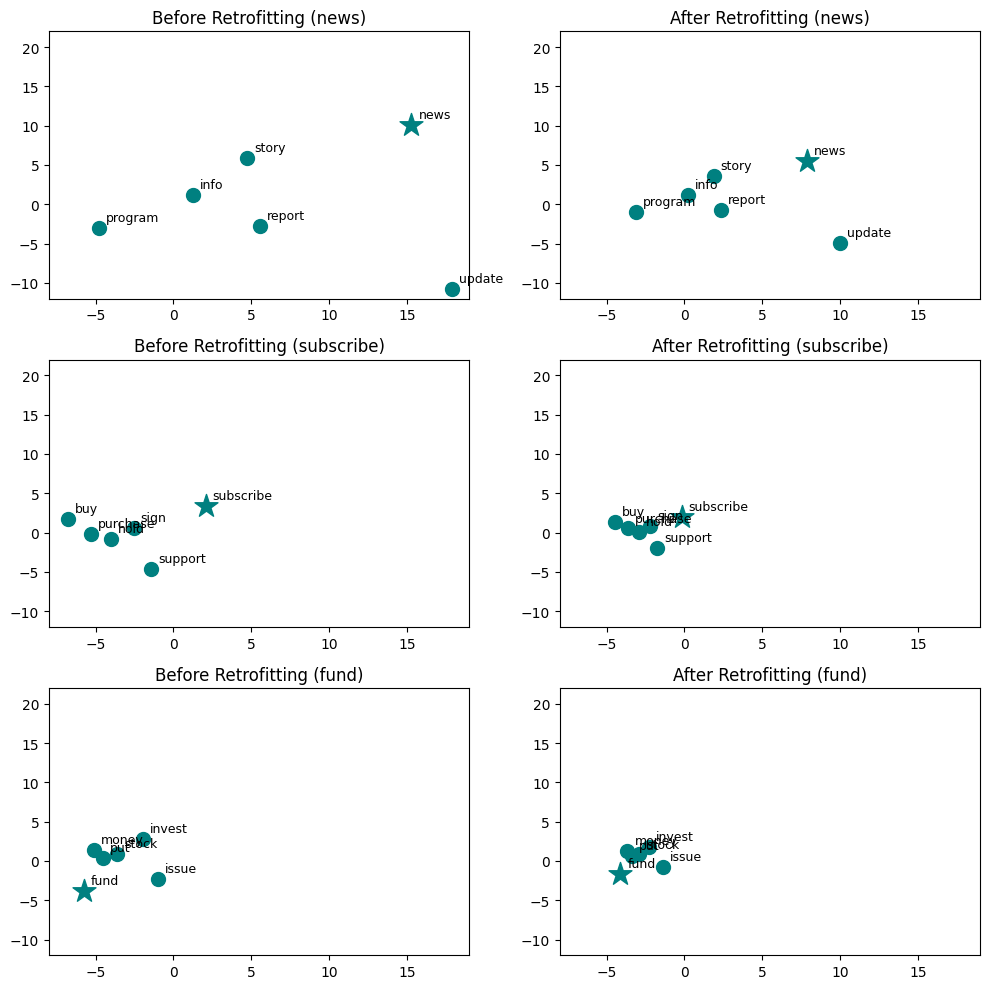

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np


# target words (first of each list) and their neighbors in the lexicon
groups = [
    ["news", "info", "program", "update", "report", "story"],
    ["subscribe", "buy", "hold", "purchase", "sign", "support"],
    ["fund", "money", "invest", "put", "issue", "stock"]
]


# flatten all words into a single list
all_words  = [w for group in groups for w in group]
# retrieve the corresponding original word vectors
all_matrix = [word_vectors[w] for w in all_words]
# fit PCA once on all words using the original vectors
pca = PCA(n_components=2).fit(all_matrix)


# let's instantiate our plot: one row per group, two columns (before and after retrofitting)
fig, axes = plt.subplots(3, 2, figsize=(10, 10))

# for each group of words (one row per group)
for row, group in enumerate(groups):

    # for each set of embedding vectors: original and retrofitted (one column each)
    for col, (vectors, title) in enumerate([
        (word_vectors,     "Before Retrofitting"),
        (retrofit_vectors, "After Retrofitting")
    ]):

        ax = axes[row, col]
        # project the group's vectors to 2D using the shared PCA
        coords = pca.transform([vectors[w] for w in group])

        for i, word in enumerate(group):
            # the first word is the target (mark it with a star)
            marker = '*' if i == 0 else 'o'
            size   = 300 if i == 0 else 100
            ax.scatter(coords[i][0], coords[i][1], color="teal", marker=marker, s=size)
            # add the word label next to the dot
            ax.annotate(word, (coords[i][0], coords[i][1]), fontsize=9,
                        textcoords="offset points", xytext=(5, 5))

        ax.set_title(f"{title} ({group[0]})")
        # fix axis limits so before and after are directly comparable
        ax.set_xlim(-8, 19)
        ax.set_ylim(-12, 22)

plt.tight_layout()
plt.show()

To quantify the effect of retrofitting, we compute the cosine similarity between each target word and its neighbors before and after retrofitting.

A higher cosine similarity after retrofitting confirms that the algorithm successfully pulled the words closer together in vector space.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

for group in groups:
    target = group[0]
    neighbors = group[1:]
    print(f"\n'{target}':")
    for neighbor in neighbors:
        before = cosine_similarity(
            word_vectors[target].reshape(1, -1),
            word_vectors[neighbor].reshape(1, -1)
        )[0][0]

        after = cosine_similarity(
            retrofit_vectors[target].reshape(1, -1),
            retrofit_vectors[neighbor].reshape(1, -1)
        )[0][0]

        print(f"  cosine({target}, {neighbor}): {before:.3f} -> {after:.3f}")


'news':
  cosine(news, info): 0.288 -> 0.439
  cosine(news, program): -0.095 -> 0.051
  cosine(news, update): 0.453 -> 0.574
  cosine(news, report): 0.340 -> 0.427
  cosine(news, story): 0.309 -> 0.392

'subscribe':
  cosine(subscribe, buy): -0.012 -> 0.300
  cosine(subscribe, hold): -0.148 -> 0.125
  cosine(subscribe, purchase): -0.031 -> 0.306
  cosine(subscribe, sign): 0.102 -> 0.377
  cosine(subscribe, support): 0.065 -> 0.298

'fund':
  cosine(fund, money): 0.558 -> 0.651
  cosine(fund, invest): 0.211 -> 0.378
  cosine(fund, put): 0.103 -> 0.230
  cosine(fund, issue): 0.344 -> 0.453
  cosine(fund, stock): 0.321 -> 0.476
